# 初回の購入体験と再購入

## 問い

**リピーターと単発購入の顧客では、初回の購入時の体験にどのような違いがあるか？**

また、見方を変えて、**初回の購入体験によって、その後の再購入率に違いがあるか**も確かめる。

## 定義 ([ADR 013](../docs/decisions/013_repeat_customer_definition.md))

- **初回購入**: 顧客の最初の購入日の注文。同じ日に複数の注文がある場合 (同時購入) は、まとめて 1 回の購入として扱う
- **再購入**: 初回購入日より後の日の注文
- **リピーター** (`is_repeat_customer`): 観察できる全期間で、再購入したことがある顧客
- **90 日以内の再購入率**: 初回購入から 90 日以内に再購入した顧客の割合。初回購入日が基準日 (2018-08-29) の 90 日以上前の顧客に絞って計算する。180 日でも同じように確かめる

## 注意

- ここでわかるのは関連であり、「初回の体験が良かったから再購入した」とは言えない。
- データの終わりに近い時期に初回購入した顧客は、再購入する時間が短い。単発購入の顧客には、まだ再購入の機会がなかった顧客も含まれる。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

client = bigquery.Client()  # プロジェクトは gcloud の設定から取得する
orders = client.query("select * from olist_mart.fct_delivered_orders").to_dataframe()
features = client.query(
    "select customer_unique_id, is_repeat_customer, purchase_day_count, reference_date from olist_mart.customer_features"
).to_dataframe()
REFERENCE_DATE = pd.Timestamp(features["reference_date"].iloc[0])
orders.shape, features.shape, REFERENCE_DATE

/home/seven/workspace/olist-data-platform/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


/home/seven/workspace/olist-data-platform/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


((96478, 18), (93358, 4), Timestamp('2018-08-29 00:00:00'))

## 1. 初回購入の体験を、顧客ごとにまとめる

初回購入日の注文 (同時購入を含む) を、顧客ごとに次のようにまとめる。

| 指標 | まとめ方 | NULL になる場合 |
|---|---|---|
| `first_late` | 初回購入日の注文のどれかが遅延したら 1 | すべての注文の配達日時がない |
| `first_delivery_days` | 配送日数の平均 | 同上 |
| `first_review_score` | レビューの評価の平均 | レビューがない |
| `first_has_review` | レビューがある注文が 1 つでもあれば TRUE | ならない |
| `first_item_count` | 商品数の合計 | ならない |
| `first_amount` | 金額 (商品価格) の合計 | ならない |

In [2]:
orders = orders.assign(
    purchase_date=pd.to_datetime(orders["order_purchase_date"]),
    is_late=orders["is_late_delivery"].astype("float"),
    delivery_days=orders["delivery_days"].astype("float"),
    review_score=orders["review_score"].astype("float"),
    has_review=orders["review_id"].notna(),
    item_count=orders["item_count"].astype("float"),
    items_amount=orders["items_amount"].astype("float"),
)

first_date = orders.groupby("customer_unique_id")["purchase_date"].min().rename("first_date")
orders = orders.join(first_date, on="customer_unique_id")
first_orders = orders[orders["purchase_date"] == orders["first_date"]]

grouped = first_orders.groupby("customer_unique_id")
first = pd.DataFrame({
    "first_date": grouped["first_date"].first(),
    "first_order_count": grouped.size(),
    # 配達日時がない注文は除いて判定する。すべてない場合は NULL
    "first_late": grouped["is_late"].max(),
    "first_delivery_days": grouped["delivery_days"].mean(),
    "first_review_score": grouped["review_score"].mean(),
    "first_has_review": grouped["has_review"].any(),
    "first_item_count": grouped["item_count"].sum(),
    "first_amount": grouped["items_amount"].sum(),
})

# 初回購入日より後の、最初の購入日 (再購入の日)
later = orders[orders["purchase_date"] > orders["first_date"]]
first["next_date"] = later.groupby("customer_unique_id")["purchase_date"].min()
first["days_to_repurchase"] = (first["next_date"] - first["first_date"]).dt.days
first["observed_days"] = (REFERENCE_DATE - first["first_date"]).dt.days
first["purchase_month"] = first["first_date"].dt.to_period("M")

first = first.join(features.set_index("customer_unique_id")[["is_repeat_customer"]], validate="one_to_one")

# mart のリピーターの判定と、初回購入日より後の購入の有無が一致することを確かめる
assert (first["is_repeat_customer"] == first["next_date"].notna()).all()
assert len(first) == len(features)
first["group"] = np.where(first["is_repeat_customer"], "repeat", "single")
first["group"].value_counts()

group
single    91343
repeat     2015
Name: count, dtype: int64

## 2. 再購入までの日数

90 日・180 日という観察期間の根拠として、リピーターの初回から再購入までの日数の分布を見る。

In [3]:
days = first["days_to_repurchase"].dropna()
print(days.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1))
print(f"90 日以内: {(days <= 90).mean():.1%} / 180 日以内: {(days <= 180).mean():.1%}")

count    2015.0
mean      114.7
std       114.7
min         1.0
25%        23.0
50%        74.0
75%       175.0
90%       288.0
max       609.0
Name: days_to_repurchase, dtype: float64
90 日以内: 54.9% / 180 日以内: 75.9%


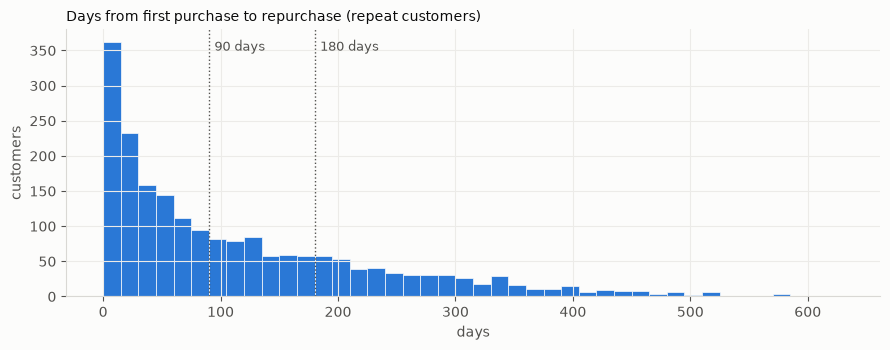

In [4]:
# グラフ内の文字は英語にする (日本語フォントがない環境でも同じように表示するため)
SURFACE = "#fcfcfb"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
SERIES = "#2a78d6"  # 単一系列のため 1 色のみ

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#d9d8d4",
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.titlecolor": TEXT_PRIMARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "axes.grid": True,
    "grid.color": "#ecebe8",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(days, bins=np.arange(0, 640, 15), color=SERIES, edgecolor=SURFACE, linewidth=0.5)
for bound in (90, 180):
    ax.axvline(bound, color=TEXT_SECONDARY, linewidth=1, linestyle=":")
    ax.annotate(f"{bound} days", (bound, ax.get_ylim()[1] * 0.92), xytext=(4, 0), textcoords="offset points",
                fontsize=9, color=TEXT_SECONDARY)
ax.set_title("Days from first purchase to repurchase (repeat customers)", fontsize=10, loc="left")
ax.set_xlabel("days")
ax.set_ylabel("customers")
fig.tight_layout()
plt.show()

## 3. リピーターと単発購入の顧客の、初回購入の体験

まず、観察期間をそろえずに比べる。平均や割合は、NULL の顧客を分母に入れない (分母の人数もあわせて示す)。

In [5]:
def first_experience(data: pd.DataFrame, by: str | pd.Series) -> pd.DataFrame:
    """グループごとに、初回購入の体験の指標を、分母の人数とあわせて返す。"""
    grouped = data.groupby(by, observed=True)
    return pd.DataFrame({
        "customers": grouped.size(),
        "late_known": grouped["first_late"].count(),
        "late_rate": grouped["first_late"].mean(),
        "delivery_days_mean": grouped["first_delivery_days"].mean(),
        "review_rate": grouped["first_has_review"].mean(),
        "reviewed": grouped["first_review_score"].count(),
        "review_mean": grouped["first_review_score"].mean(),
        "low_review_rate": grouped["first_review_score"].apply(lambda s: (s.dropna() <= 3).mean()),
        "items_mean": grouped["first_item_count"].mean(),
        "amount_median": grouped["first_amount"].median(),
    })


first_experience(first, "group").round(3)

,customers,late_known,late_rate,delivery_days_mean,review_rate,reviewed,review_mean,low_review_rate,items_mean,amount_median
group,,,,,,,,,,
repeat,2015,2015,0.051,11.876,0.994,2002,4.281,0.177,1.249,87.99
single,91343,91335,0.069,12.524,0.993,90741,4.151,0.212,1.148,88.00


### 初回購入の月ごとの人数

初回購入が最近の顧客ほど、再購入する時間が短いため、リピーターの割合は下がるはずである。

In [6]:
by_month = first.groupby("purchase_month").agg(
    customers=("group", "size"),
    repeat=("is_repeat_customer", "sum"),
)
by_month["repeat_share"] = by_month["repeat"] / by_month["customers"]
by_month.round(3)

,customers,repeat,repeat_share
purchase_month,,,
2016-09,1,0,0.0
2016-10,262,10,0.038
2016-12,1,1,1.0
2017-01,717,32,0.045
2017-02,1628,53,0.033
2017-03,2503,91,0.036
2017-04,2256,84,0.037
2017-05,3451,141,0.041
2017-06,3037,119,0.039


### 初回購入の月の構成をそろえた比較 (直接法による調整)

リピーターは、初回購入が早い時期に偏っている。購入体験は時期によって大きく変わる ([06_segment_analysis.ipynb](06_segment_analysis.ipynb)) ため、
両グループの月ごとの値を、全顧客の初回購入月の構成で重み付けして平均する。対象は、2017-01〜2018-08 に初回購入した顧客。

In [7]:
def period_adjusted(data: pd.DataFrame, metric: str, by: str) -> pd.DataFrame:
    """グループごとの指標を、調整前と、初回購入月の構成をそろえた調整後で返す。"""
    data = data[data[metric].notna()]
    weights = data["purchase_month"].value_counts(normalize=True)
    monthly = data.groupby(["purchase_month", by], observed=True)[metric].mean().unstack(by)
    w = monthly.notna().mul(weights.reindex(monthly.index), axis=0)
    adjusted = monthly.mul(weights.reindex(monthly.index), axis=0).sum() / w.sum()
    raw = data.groupby(by, observed=True)[metric].mean()
    return pd.DataFrame({"raw": raw, "period_adjusted": adjusted})


in_period = first[first["purchase_month"] >= pd.Period("2017-01")]
pd.concat(
    {metric: period_adjusted(in_period, metric, "group") for metric in ("first_late", "first_delivery_days", "first_review_score")},
    axis=1,
).round(3)

first_late                 first_delivery_days                 first_review_score                
              raw period_adjusted                 raw period_adjusted                raw period_adjusted
group                                                                                                   
repeat      0.051           0.057              11.851          11.462              4.280           4.281
single      0.069           0.069              12.504          12.512              4.151           4.151

## 4. 初回購入の体験ごとの、90 日以内の再購入率

見方を変えて、初回購入の体験ごとに、その後 90 日以内に再購入した割合を比べる。
初回購入日が基準日の 90 日以上前の顧客に絞る (90 日を観察できる顧客)。

- `repurchase_rate`: 90 日以内に再購入した顧客の割合
- `ci_low`・`ci_high`: 95% 信頼区間 (正規近似)

In [8]:
def repurchase_rate(data: pd.DataFrame, by: str | pd.Series, window: int) -> pd.DataFrame:
    """グループごとに、window 日以内の再購入率と 95% 信頼区間を返す (window 日を観察できる顧客のみ)。"""
    observable = data["observed_days"] >= window
    data = data[observable]
    if isinstance(by, pd.Series):
        by = by[observable]
    repurchased = data["days_to_repurchase"] <= window  # 再購入がなければ NaN のため False
    grouped = repurchased.groupby(by, observed=True)
    rate = grouped.mean()
    n = grouped.size()
    se = np.sqrt(rate * (1 - rate) / n)
    return pd.DataFrame({
        "customers": n,
        "repurchased": grouped.sum(),
        "repurchase_rate": rate,
        "ci_low": rate - 1.96 * se,
        "ci_high": rate + 1.96 * se,
    })


late_label = first["first_late"].map({0.0: "on_time", 1.0: "late"}).fillna("unknown")
review_label = first["first_review_score"].pipe(
    lambda s: pd.cut(s, bins=[0, 2, 3, 4, 5], labels=["(0, 2]", "(2, 3]", "(3, 4]", "(4, 5]"])
).astype("string").fillna("no_review")

for window in (90, 180):
    print(f"--- {window} 日以内 ---")
    print(f"全体: {repurchase_rate(first, pd.Series('all', index=first.index), window).iloc[0]['repurchase_rate']:.2%}")
    display(repurchase_rate(first, late_label, window).round(4))
    display(repurchase_rate(first, review_label, window).round(4))

--- 90 日以内 ---
全体: 1.30%


,customers,repurchased,repurchase_rate,ci_low,ci_high
first_late,,,,,
late,5727,58,0.0101,0.0075,0.0127
on_time,69658,920,0.0132,0.0124,0.0141
unknown,2,0,0.0000,0.0000,0.0000


,customers,repurchased,repurchase_rate,ci_low,ci_high
first_review_score,,,,,
"(0, 2]",10141,104,0.0103,0.0083,0.0122
"(2, 3]",6460,70,0.0108,0.0083,0.0134
"(3, 4]",14998,179,0.0119,0.0102,0.0137
"(4, 5]",43256,621,0.0144,0.0132,0.0155
no_review,532,4,0.0075,0.0002,0.0149


--- 180 日以内 ---
全体: 1.98%


,customers,repurchased,repurchase_rate,ci_low,ci_high
first_late,,,,,
late,3846,61,0.0159,0.0119,0.0198
on_time,52188,1048,0.0201,0.0189,0.0213
unknown,2,0,0.0000,0.0000,0.0000


,customers,repurchased,repurchase_rate,ci_low,ci_high
first_review_score,,,,,
"(0, 2]",7382,123,0.0167,0.0137,0.0196
"(2, 3]",4873,94,0.0193,0.0154,0.0232
"(3, 4]",11167,204,0.0183,0.0158,0.0208
"(4, 5]",32197,683,0.0212,0.0196,0.0228
no_review,417,5,0.0120,0.0015,0.0224


`first_review_score` は、初回購入日に複数の注文がある顧客では平均になるため、整数でない値もとる。そのため、区分は区間で表す (例: `(2, 3]` は 2 より大きく 3 以下。ほとんどの顧客は整数の値で、`(2, 3]` は評価 3 の顧客)。

### 再購入率の考察

- 90 日以内の再購入率は、全体で 1.30% と非常に低い。
- 初回購入で遅延した顧客の再購入率 (1.01%) は、遅延しなかった顧客 (1.32%) より低い。ただし、信頼区間はわずかに重なっている。
- 初回のレビューの評価が高いほど、再購入率は高い (評価 2 以下 1.03% → 4 より大きい 1.44%)。
- 180 日以内でも、遅延した顧客の方が再購入率は低く (1.59% と 2.01%)、レビューは最も高い区分の再購入率が最も高い (2.12%)。ただし、レビューの中間の区分 (`(2, 3]` と `(3, 4]`) では順序が入れ替わる。

### 初回購入の時期ごとの確認

遅延の有無による再購入率の差が、特定の時期だけのものでないかを、初回購入の四半期ごとに確かめる (90 日以内)。

In [9]:
observable = first[first["observed_days"] >= 90]
quarter = observable["first_date"].dt.to_period("Q")
repurchased = observable["days_to_repurchase"] <= 90
table = repurchased.groupby([quarter, late_label[observable.index]]).agg(["size", "mean"]).unstack()
table = table[table.index >= pd.Period("2017Q1")]
table.round(4)

size                     mean                
first_late    late  on_time unknown    late on_time unknown
first_date                                                 
2017Q1       186.0   4662.0     NaN  0.0054  0.0112     NaN
2017Q2       349.0   8394.0     1.0  0.0143  0.0147     0.0
2017Q3       394.0  11419.0     NaN  0.0178  0.0152     NaN
2017Q4      1472.0  15253.0     1.0  0.0075  0.0126     0.0
2018Q1      2595.0  17309.0     NaN  0.0104  0.0119     NaN
2018Q2       728.0  12360.0     NaN  0.0096  0.0139     NaN

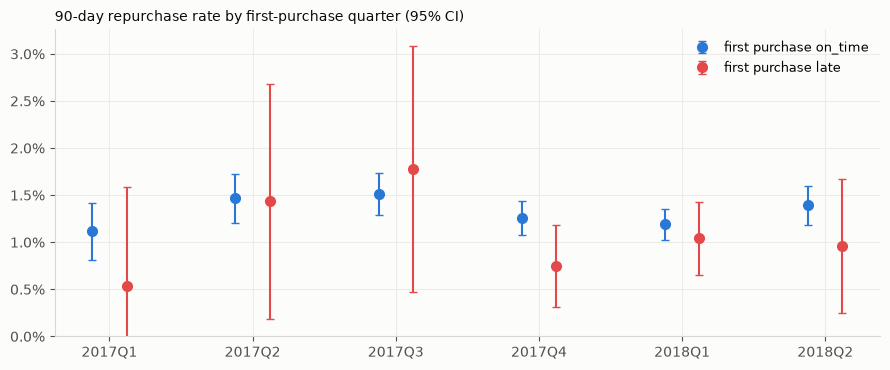

In [10]:
# 再購入率は低く、四半期ごとの差はばらつきが大きいため、信頼区間とあわせて図にする
LATE_COLORS = {"on_time": "#2a78d6", "late": "#e34948"}
fig, ax = plt.subplots(figsize=(9, 3.8))
quarters = table.index
x = np.arange(len(quarters))
for offset, label in ((-0.12, "on_time"), (0.12, "late")):
    rate = table[("mean", label)]
    n = table[("size", label)]
    se = np.sqrt(rate * (1 - rate) / n)
    ax.errorbar(x + offset, rate, yerr=1.96 * se, fmt="o", color=LATE_COLORS[label], markersize=7,
                capsize=3, linewidth=1.5, label=f"first purchase {label}")
ax.set_xticks(x, [str(q) for q in quarters])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_ylim(bottom=0)
ax.set_title("90-day repurchase rate by first-purchase quarter (95% CI)", fontsize=10, loc="left")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

- 遅延した顧客の再購入率が、遅延しなかった顧客より低いのは、6 つの四半期のうち 4 つ (2017Q1・2017Q4・2018Q1・2018Q2)。2017Q2 はほぼ同じで、2017Q3 は逆になっている。
- 遅延した顧客は四半期ごとに数百〜2,600 人で、再購入した人数は少なく、信頼区間が広い。遅延と再購入率の関連は、時期によらず安定しているとまでは言えない。

## まとめ

### データから確認できた事実

- **リピーターの初回購入の体験は、単発購入の顧客よりやや良い**。遅延率 5.1% と 6.9%、配送日数 11.9 日と 12.5 日、レビュー 4.28 と 4.15。
- リピーターは初回購入が早い時期に偏っている。初回購入の月の構成をそろえても差は残るが、遅延率の差は小さくなる (5.7% と 6.9%)。レビューの差はほとんど変わらない。
- 初回購入の金額 (中央値 約 88) は、両グループでほぼ同じ。
- **90 日以内の再購入率は、全体で 1.30% と非常に低い**。初回の体験が良いほど、再購入率はやや高い (遅延なし 1.32%・遅延あり 1.01%、レビューが 4 より大きい 1.44%・2 以下 1.03%)。180 日以内でも、遅延の有無と、レビューの最も高い区分・最も低い区分の関係は同じ。
- 遅延と再購入率の関連は、初回購入の四半期によっては見られない。
- 再購入までの日数は、中央値 74 日。15 日以内の再購入が最も多い。

### 考えられる解釈

- 初回の購入体験と再購入には、弱い関連がある。ただし、体験が良かったことが再購入の理由なのか、ほかの要因 (購入した商品のカテゴリ、配送先の地域など) が両方に影響しているのかは、この分析では区別できない。
- 体験が良かった顧客でも、再購入率は 1〜2% にとどまる。**再購入の少なさは、初回の購入体験だけでは説明できない**。
- 関連がそのまま因果関係だったと仮定しても、影響は小さい。例えば、遅延した顧客 (90 日を観察できる顧客の約 7.6%) の再購入率が、遅延しなかった顧客と同じ 1.32% になったとしても、全体の再購入率は 1.30% から約 1.32% に上がるだけである。

### 検証すべき施策の仮説

- **再購入を増やす施策は、配送品質の改善とは別に考える**: 配送品質の改善は、満足度 (レビュー) の向上には意味があると考えられるが、再購入を増やす主な手段にはなりにくい。再購入のきっかけ (再購入を促す連絡、関連する商品の提案など) を作る施策を、別に検討する。
- **再購入が起きやすい時期に働きかける**: 再購入は初回から早い時期 (15 日以内) に最も多い。初回購入の直後の働きかけが候補になる。
- **再購入しやすい顧客の特徴を調べる**: 購入した商品のカテゴリや地域によって、再購入率に違いがあるかを確かめる (今回は対象外)。

これらは、このデータから立てた仮説であり、施策の効果は検証していない。